# import needed libraries

In [44]:
import os
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import random
import shutil
from PIL import Image
import torch
import torch.nn as nn 
import torch.optim as optim
from torchvision import models
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import torch.cuda.amp as amp  
import warnings
warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
root = "/kaggle/input/datasets/salmansajid05/oral-diseases"
skip = "yolo"
exts = (".jpg", ".jpeg", ".png")
for cls in sorted(os.listdir(root)):
    cp = os.path.join(root, cls)
    if not os.path.isdir(cp) or skip in cls.lower():
        continue
    orig = aug = 0
    for dp, _, files in os.walk(cp):
        n = sum(f.lower().endswith(exts) for f in files)
        if "aug" in dp.lower():
            aug += n
        else:
            orig += n
    print(f"{cls}: original={orig}, augmented={aug}")

Calculus: original=1296, augmented=0
Data caries: original=219, augmented=2382
Gingivitis: original=2349, augmented=0
Mouth Ulcer: original=265, augmented=2541
Tooth Discoloration: original=183, augmented=1834
hypodontia: original=1251, augmented=0


In [3]:
origin_dirs = {
    'Calculus' : f'{root}/Calculus/Calculus',
    'Caries': f'{root}/Data caries/Data caries/caries orignal data set/done',
    'Gingivitis': f'{root}/Gingivitis/Gingivitis',
    'Ulcers': f'{root}/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset',
    'Tooth Discoloration': f'{root}/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset',
    'Hypodontia': f'{root}/hypodontia/hypodontia'
}

In [4]:
base_dir = '/kaggle/working/dataset'
splits = ['train', 'val', 'test']
classes = list(origin_dirs.keys())

In [5]:
for split in splits:
    for class_name in classes:
        os.makedirs(
            os.path.join(base_dir, split, class_name), exist_ok=True
        )

# Function to copy and split images

In [6]:
def distribute_images (class_name, image_paths):
    train_paths, test_paths = train_test_split(image_paths, test_size=0.1, random_state=42)
    train_paths, val_paths = train_test_split(train_paths, test_size=0.2, random_state=42)
    
    split_paths = {'train': train_paths, 'val': val_paths, 'test': test_paths}
    for split, paths in split_paths.items() :
        for img_path in paths:
            final_path = os.path.join(base_dir, split, class_name, os.path.basename(img_path))
            shutil.copy(img_path,final_path)

In [7]:
for class_name, original_dir in origin_dirs.items():
    images_path = [os.path.join(root, file) for root, _, files in os.walk(original_dir)
                  for file in files if file.lower().endswith(('.jpg', '.jpeg', '.png'))]

    if images_path:
        distribute_images(class_name, images_path)

print('Done!')

Done!


In [23]:
random.seed(42)
torch.manual_seed(42)
np.random.seed(42)

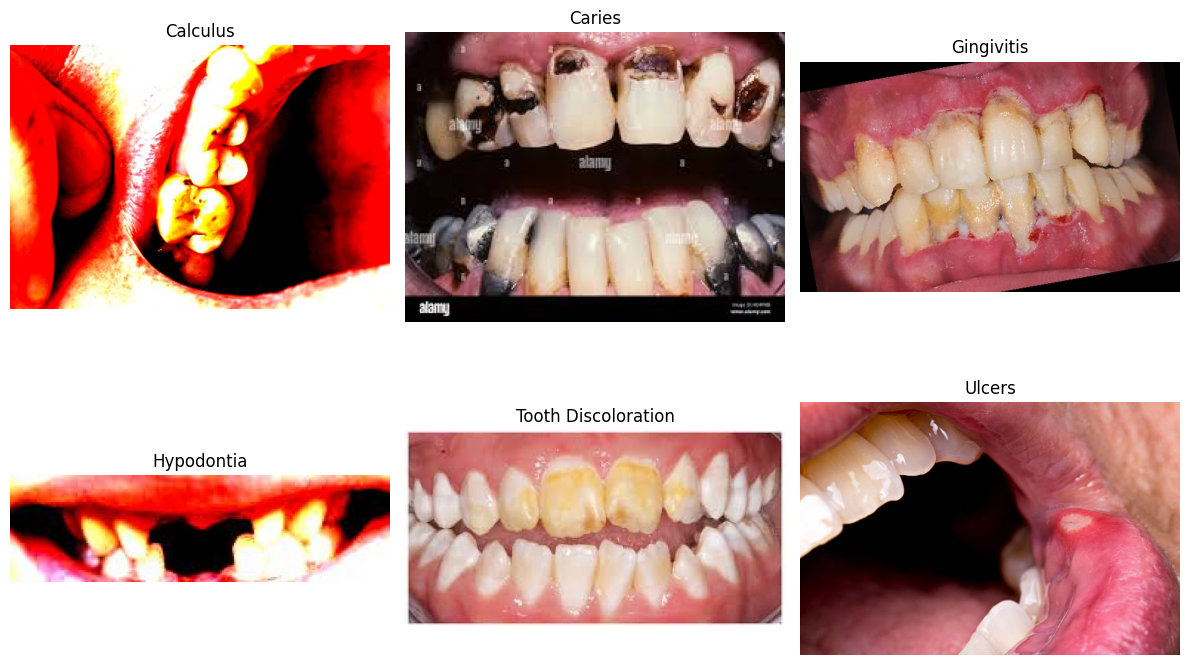

In [14]:
classes = sorted(os.listdir(train_dir))
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, c in zip(axes.flatten(), classes):
    folder = os.path.join(train_dir, c)
    img_path = os.path.join(folder, random.choice(os.listdir(folder)))
    ax.imshow(Image.open(img_path).convert("RGB"))
    ax.set_title(c)
    ax.axis("off")

plt.tight_layout()
plt.show()

# data augmentation

In [34]:
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [35]:
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

train_dataset = ImageFolder(train_dir, transform=train_transforms)
val_dataset = ImageFolder(val_dir, transform=val_transforms)
test_dataset = ImageFolder(test_dir, transform=val_transforms)

In [36]:
print(train_dataset.class_to_idx)

{'Calculus': 0, 'Caries': 1, 'Gingivitis': 2, 'Hypodontia': 3, 'Tooth Discoloration': 4, 'Ulcers': 5}


# Data loaders with optimized settings

In [37]:
batch_size = 32  

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

# Compute Class Weight

In [38]:
targets = np.array(train_dataset.targets)
weights = compute_class_weight("balanced", classes=np.unique(targets), y=targets)
class_weights = torch.tensor(weights, dtype=torch.float).to(device)

print(train_dataset.classes)
print(weights.round(2))

['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Tooth Discoloration', 'Ulcers']
[0.72 4.25 0.39 0.74 5.09 3.51]


# Model Preparing & Training

In [42]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class OralResCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, 2, 3, bias=False),  # 224 -> 112
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1),                  # 112 -> 56
        )
        self.layers = nn.Sequential(
            ResBlock(64, 64),
            ResBlock(64, 128, stride=2),    # 56 -> 28
            ResBlock(128, 256, stride=2),   # 28 -> 14
            ResBlock(256, 512, stride=2),   # 14 -> 7
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.layers(self.stem(x))))

model     = OralResCNN(num_classes).to(device)
epochs    = 60
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M params")

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

best_acc, best_state = 0, None
history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    scheduler.step(va_acc)
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    if va_acc > best_acc:
        best_acc = va_acc
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

model.load_state_dict(best_state)
torch.save(best_state, "best_oral_rescnn_v3.pth")
print("Best val acc:", best_acc)

4.90887 M params
Epoch 01 | train loss 1.973 acc 0.266 | val loss 2.448 acc 0.281
Epoch 02 | train loss 1.802 acc 0.379 | val loss 2.545 acc 0.242
Epoch 03 | train loss 1.712 acc 0.438 | val loss 2.393 acc 0.310
Epoch 04 | train loss 1.673 acc 0.455 | val loss 2.090 acc 0.481
Epoch 05 | train loss 1.627 acc 0.506 | val loss 2.015 acc 0.524
Epoch 06 | train loss 1.605 acc 0.507 | val loss 2.020 acc 0.471
Epoch 07 | train loss 1.568 acc 0.549 | val loss 1.979 acc 0.612
Epoch 08 | train loss 1.558 acc 0.533 | val loss 1.993 acc 0.521
Epoch 09 | train loss 1.548 acc 0.557 | val loss 2.519 acc 0.350
Epoch 10 | train loss 1.525 acc 0.566 | val loss 2.044 acc 0.611
Epoch 11 | train loss 1.527 acc 0.577 | val loss 2.282 acc 0.434
Epoch 12 | train loss 1.445 acc 0.615 | val loss 1.809 acc 0.708
Epoch 13 | train loss 1.395 acc 0.643 | val loss 1.991 acc 0.553
Epoch 14 | train loss 1.408 acc 0.630 | val loss 1.903 acc 0.629
Epoch 15 | train loss 1.385 acc 0.655 | val loss 2.131 acc 0.440
Epoch 16

Test acc: 0.8014311270125224
                     precision    recall  f1-score   support

           Calculus      0.696     0.738     0.716       130
             Caries      0.400     0.636     0.491        22
         Gingivitis      0.872     0.753     0.808       235
         Hypodontia      0.930     0.944     0.937       126
Tooth Discoloration      0.682     0.789     0.732        19
             Ulcers      0.818     1.000     0.900        27

           accuracy                          0.801       559
          macro avg      0.733     0.810     0.764       559
       weighted avg      0.816     0.801     0.805       559



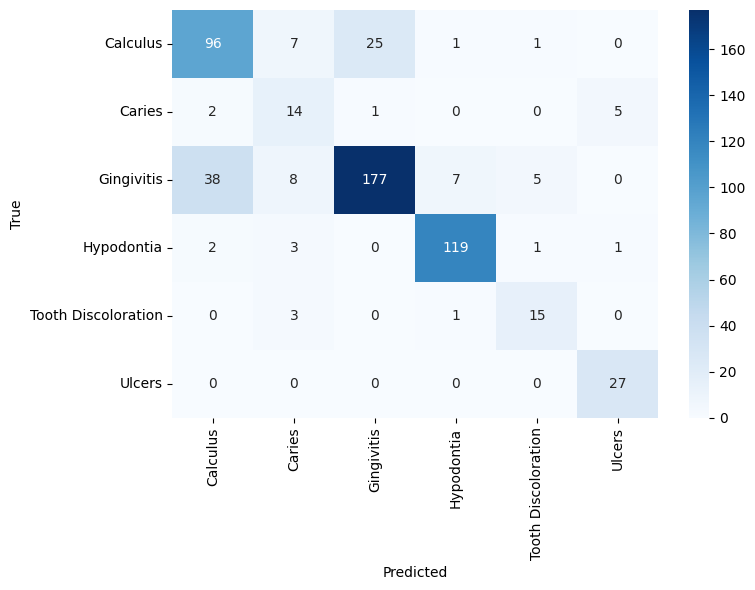

In [43]:
model.load_state_dict(best_state)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds += out.argmax(1).cpu().tolist()
        all_labels += y.tolist()

class_names = test_dataset.classes
print("Test acc:", (np.array(all_preds) == np.array(all_labels)).mean())
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

# Pre-trained Models

# ResNet Model

In [45]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class OralResCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, 2, 3, bias=False),  # 224 -> 112
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1),                  # 112 -> 56
        )
        self.layers = nn.Sequential(
            ResBlock(64, 64),
            ResBlock(64, 128, stride=2),    # 56 -> 28
            ResBlock(128, 256, stride=2),   # 28 -> 14
            ResBlock(256, 512, stride=2),   # 14 -> 7
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.layers(self.stem(x))))

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, num_classes))
model = model.to(device)

epochs    = 25
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M params")

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

best_acc, best_state = 0, None
history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    scheduler.step(va_acc)
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    if va_acc > best_acc:
        best_acc = va_acc
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

model.load_state_dict(best_state)
torch.save(best_state, "best_oral_resnet18.pth")
print("Best val acc:", best_acc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s] 


11.17959 M params
Epoch 01 | train loss 1.532 acc 0.551 | val loss 1.799 acc 0.727
Epoch 02 | train loss 1.215 acc 0.730 | val loss 1.719 acc 0.763
Epoch 03 | train loss 1.135 acc 0.781 | val loss 1.749 acc 0.687
Epoch 04 | train loss 1.114 acc 0.797 | val loss 1.666 acc 0.786
Epoch 05 | train loss 1.059 acc 0.821 | val loss 1.649 acc 0.808
Epoch 06 | train loss 1.046 acc 0.829 | val loss 1.650 acc 0.806
Epoch 07 | train loss 1.028 acc 0.846 | val loss 1.607 acc 0.828
Epoch 08 | train loss 1.021 acc 0.855 | val loss 1.618 acc 0.831
Epoch 09 | train loss 1.020 acc 0.845 | val loss 1.614 acc 0.817
Epoch 10 | train loss 1.023 acc 0.859 | val loss 1.599 acc 0.832
Epoch 11 | train loss 1.014 acc 0.860 | val loss 1.614 acc 0.802
Epoch 12 | train loss 1.005 acc 0.864 | val loss 1.620 acc 0.802
Epoch 13 | train loss 1.005 acc 0.872 | val loss 1.625 acc 0.806
Epoch 14 | train loss 1.001 acc 0.865 | val loss 1.605 acc 0.822
Epoch 15 | train loss 0.980 acc 0.880 | val loss 1.595 acc 0.825
Epoch 1

Test acc: 0.8264758497316637
                     precision    recall  f1-score   support

           Calculus      0.688     0.731     0.709       130
             Caries      0.594     0.864     0.704        22
         Gingivitis      0.859     0.779     0.817       235
         Hypodontia      0.953     0.976     0.965       126
Tooth Discoloration      0.800     0.842     0.821        19
             Ulcers      0.963     0.963     0.963        27

           accuracy                          0.826       559
          macro avg      0.810     0.859     0.830       559
       weighted avg      0.833     0.826     0.828       559



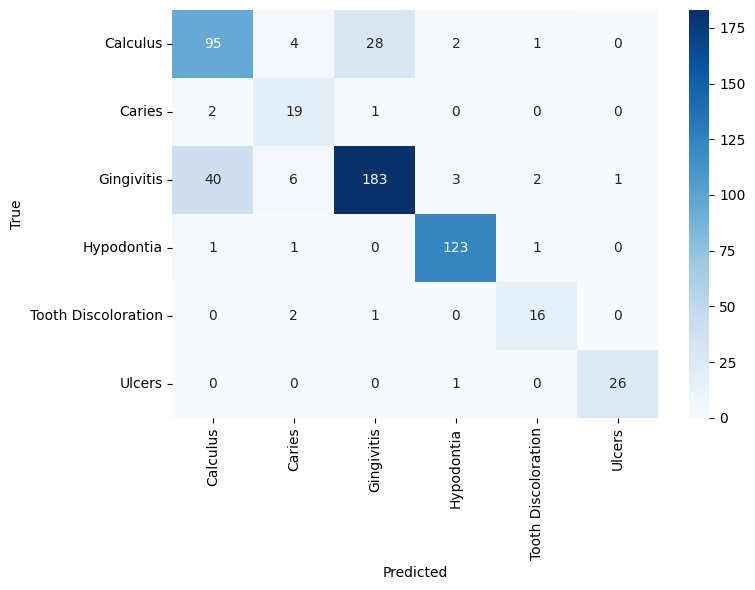

In [46]:
model = models.resnet18(weights=None)
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, num_classes))
model.load_state_dict(torch.load("best_oral_resnet18.pth", map_location=device))
model = model.to(device)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds += out.argmax(1).cpu().tolist()
        all_labels += y.tolist()

class_names = test_dataset.classes
print("Test acc:", (np.array(all_preds) == np.array(all_labels)).mean())
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

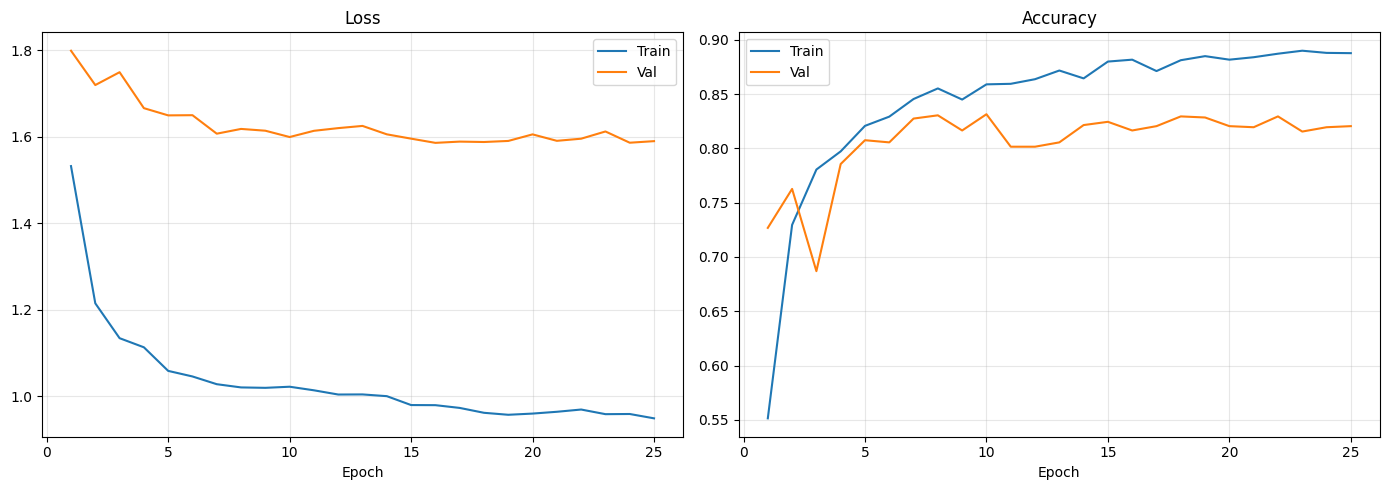

In [47]:
epochs_range = range(1, len(history["tr_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["tr_loss"], label="Train")
axes[0].plot(epochs_range, history["va_loss"], label="Val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["tr_acc"], label="Train")
axes[1].plot(epochs_range, history["va_acc"], label="Val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

# Efficient Model

In [48]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class OralResCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, 2, 3, bias=False),  # 224 -> 112
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1),                  # 112 -> 56
        )
        self.layers = nn.Sequential(
            ResBlock(64, 64),
            ResBlock(64, 128, stride=2),    # 56 -> 28
            ResBlock(128, 256, stride=2),   # 28 -> 14
            ResBlock(256, 512, stride=2),   # 14 -> 7
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.layers(self.stem(x))))

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.classifier[1].in_features, num_classes),
)
model = model.to(device)

epochs    = 25
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M params")

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += x.size(0)
    return total_loss / total, correct / total

best_acc, best_state = 0, None
history = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": []}

for epoch in range(1, epochs + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    scheduler.step(va_acc)
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    if va_acc > best_acc:
        best_acc = va_acc
        best_state = copy.deepcopy(model.state_dict())
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

model.load_state_dict(best_state)
torch.save(best_state, "best_oral_effnet_b0.pth")
print("Best val acc:", best_acc)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


4.015234 M params
Epoch 01 | train loss 1.469 acc 0.593 | val loss 1.714 acc 0.769
Epoch 02 | train loss 1.166 acc 0.764 | val loss 1.624 acc 0.808
Epoch 03 | train loss 1.085 acc 0.810 | val loss 1.635 acc 0.813
Epoch 04 | train loss 1.034 acc 0.839 | val loss 1.609 acc 0.833
Epoch 05 | train loss 1.017 acc 0.852 | val loss 1.595 acc 0.821
Epoch 06 | train loss 1.005 acc 0.852 | val loss 1.581 acc 0.842
Epoch 07 | train loss 0.977 acc 0.864 | val loss 1.586 acc 0.833
Epoch 08 | train loss 0.982 acc 0.870 | val loss 1.559 acc 0.827
Epoch 09 | train loss 0.978 acc 0.864 | val loss 1.569 acc 0.838
Epoch 10 | train loss 1.002 acc 0.851 | val loss 1.574 acc 0.839
Epoch 11 | train loss 0.978 acc 0.876 | val loss 1.546 acc 0.848
Epoch 12 | train loss 0.969 acc 0.875 | val loss 1.550 acc 0.837
Epoch 13 | train loss 0.960 acc 0.880 | val loss 1.540 acc 0.854
Epoch 14 | train loss 0.955 acc 0.880 | val loss 1.557 acc 0.843
Epoch 15 | train loss 0.956 acc 0.877 | val loss 1.558 acc 0.844
Epoch 1

Test acc: 0.8568872987477638
                     precision    recall  f1-score   support

           Calculus      0.700     0.808     0.750       130
             Caries      0.760     0.864     0.809        22
         Gingivitis      0.891     0.800     0.843       235
         Hypodontia      0.976     0.976     0.976       126
Tooth Discoloration      0.895     0.895     0.895        19
             Ulcers      0.964     1.000     0.982        27

           accuracy                          0.857       559
          macro avg      0.864     0.890     0.876       559
       weighted avg      0.864     0.857     0.859       559



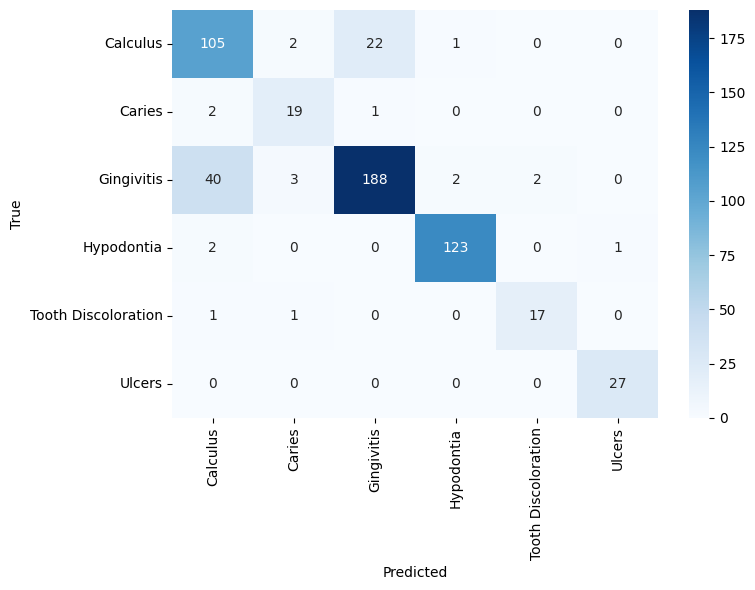

In [49]:
model = models.efficientnet_b0(weights=None)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[1].in_features, num_classes))
model.load_state_dict(torch.load("best_oral_effnet_b0.pth", map_location=device))
model = model.to(device)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        all_preds += out.argmax(1).cpu().tolist()
        all_labels += y.tolist()

class_names = test_dataset.classes
print("Test acc:", (np.array(all_preds) == np.array(all_labels)).mean())
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

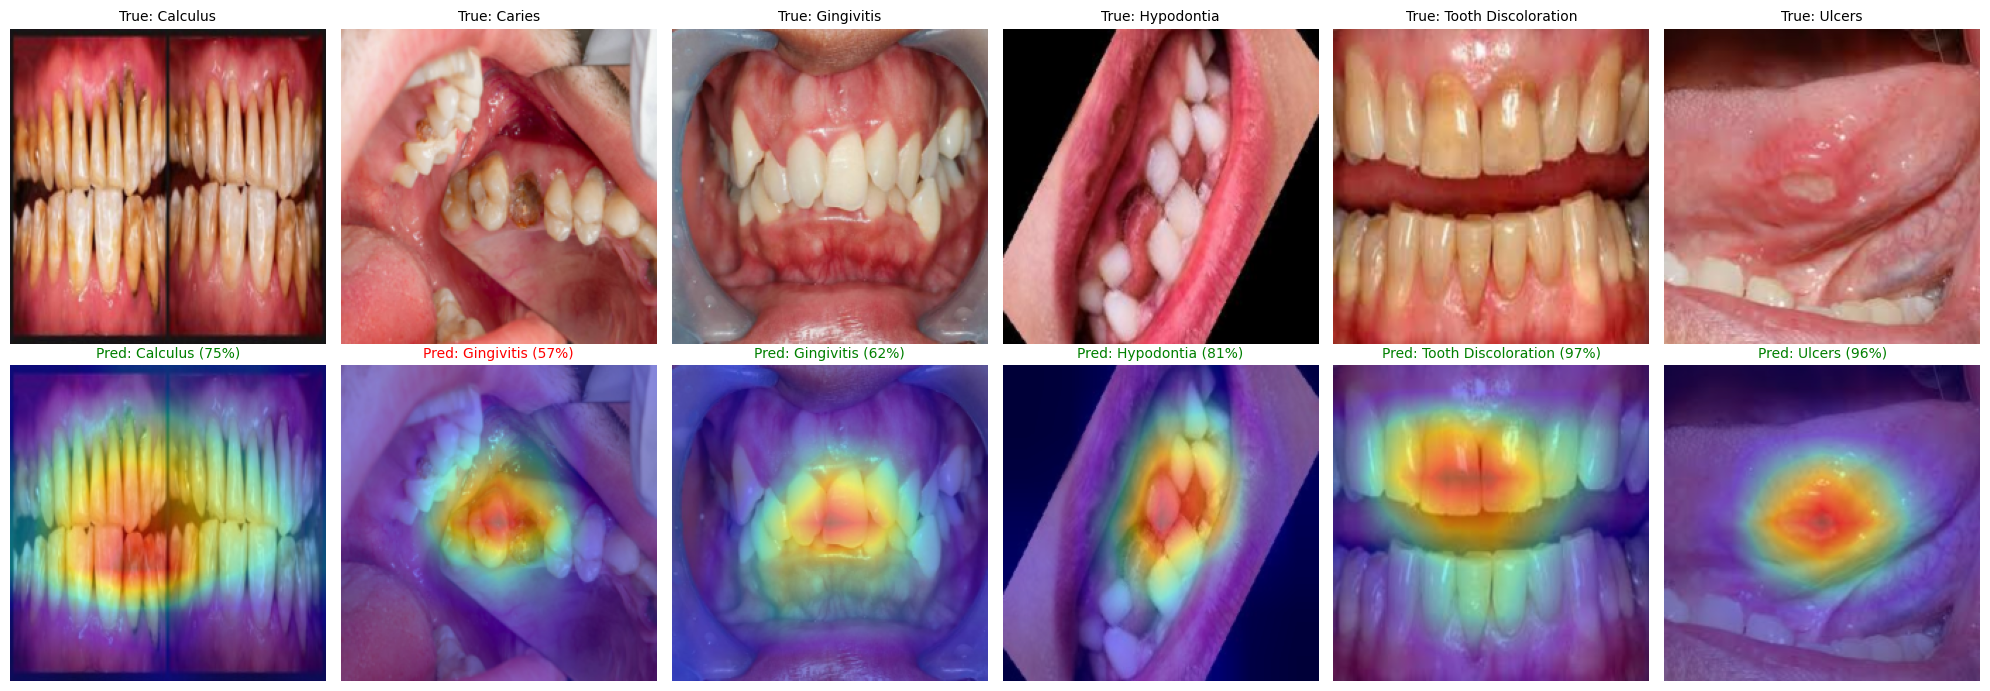

In [52]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.acts, self.grads = None, None
        target_layer.register_forward_hook(self._fwd)

    def _fwd(self, m, i, o):
        self.acts = o
        o.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        self.model.zero_grad()
        out = self.model(x)
        idx = out.argmax(1).item()
        out[0, idx].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.numpy(), idx, out.softmax(1)[0, idx].item()

model.eval()
cam_engine = GradCAM(model, model.features[-1])   # ResNet18: model.layer4[-1]

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for c, cname in enumerate(class_names):
    idxs = [i for i, (_, l) in enumerate(test_dataset.samples) if l == c]
    x, y = test_dataset[random.choice(idxs)]
    cam, pred, conf = cam_engine(x.unsqueeze(0).to(device))

    img = (x * std + mean).permute(1, 2, 0).clamp(0, 1).numpy()
    axes[0, c].imshow(img)
    axes[0, c].set_title(f"True: {cname}", fontsize=10)
    axes[0, c].axis("off")

    color = "green" if pred == y else "red"
    axes[1, c].imshow(img)
    axes[1, c].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, c].set_title(f"Pred: {class_names[pred]} ({conf:.0%})", color=color, fontsize=10)
    axes[1, c].axis("off")

plt.tight_layout()
plt.savefig("gradcam.png", dpi=150)
plt.show()

In [56]:
model.features[-1]._forward_hooks.clear()

In [57]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

torch.save(model.state_dict(), "oral_effnet_b0.pth")

infer_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(img: Image.Image):
    model.eval()
    x = infer_tf(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = model(x).softmax(1)[0].cpu()
    return {class_names[i]: float(probs[i]) for i in range(len(class_names))}

img = Image.open(test_dataset.samples[0][0])
print(predict(img))

{'Calculus': 0.11109621077775955, 'Caries': 0.13172173500061035, 'Gingivitis': 0.5753297209739685, 'Hypodontia': 0.009978638030588627, 'Tooth Discoloration': 0.09688042849302292, 'Ulcers': 0.07499321550130844}


## Model Comparison

All models were trained on the same split (70/15/15, stratified), with the same augmentation, class-weighted loss with label smoothing (0.1), and evaluated on the held-out test set (559 images).

| Model | Pretrained | Params | Epochs | Test Acc | Macro F1 | Weighted F1 |
|---|---|---|---|---|---|---|
| Custom ResCNN (from scratch) | No | 4.9M | 60 | 80.1% | 0.764 | 0.805 |
| ResNet18 | ImageNet | ~11.2M | 25 | 82.6% | 0.830 | 0.828 |
| **EfficientNet-B0** | ImageNet | ~4.0M | 25 | **85.7%** | **0.876** | **0.859** |

### Per-class F1-score

| Class | Test samples | ResCNN | ResNet18 | EfficientNet-B0 |
|---|---|---|---|---|
| Calculus | 130 | 0.716 | 0.709 | **0.750** |
| Caries | 22 | 0.491 | 0.704 | **0.809** |
| Gingivitis | 235 | 0.808 | 0.817 | **0.843** |
| Hypodontia | 126 | 0.937 | 0.965 | **0.976** |
| Tooth Discoloration | 19 | 0.732 | 0.821 | **0.895** |
| Ulcers | 27 | 0.900 | 0.963 | **0.982** |

### Observations
- **EfficientNet-B0 performed best** on every class, with the fewest parameters among the pretrained models.
- Transfer learning improved the minority classes the most (Caries F1: 0.49 → 0.81).
- **Calculus vs. Gingivitis** remains the main source of errors (~62 of 79 mistakes for EfficientNet-B0) across all three models.

### Limitations
- Visual inspection of misclassified images suggests label ambiguity: many images show features of both conditions, while the dataset is single-label.
- Some images in the "original" folders appear to be augmented (rotated, color-distorted).
- Caries (22) and Tooth Discoloration (19) have very small test sets, so their metrics are sensitive to a few images.